In [ ]:
import pandas as pd

df = pd.read_csv('iris.csv', names=['sepal length','sepal width','petal length','petal width','target'])
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'iris.data'

In [ ]:
# X is data frame of features; y is data frame of target
features = ['sepal length','sepal width','petal length','petal width']
X = df[features]
y = df["target"]

In [ ]:
y.value_counts()

target
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

In [ ]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_standardized = sc.fit_transform(X)
X_standardized_pd = pd.DataFrame(X_standardized,columns=features)
X_standardized_pd.head()


,sepal length,sepal width,petal length,petal width
0,-0.900681,1.032057,-1.341272,-1.312977
1,-1.143017,-0.124958,-1.341272,-1.312977
2,-1.385353,0.337848,-1.398138,-1.312977
3,-1.506521,0.106445,-1.284407,-1.312977
4,-1.021849,1.263460,-1.341272,-1.312977


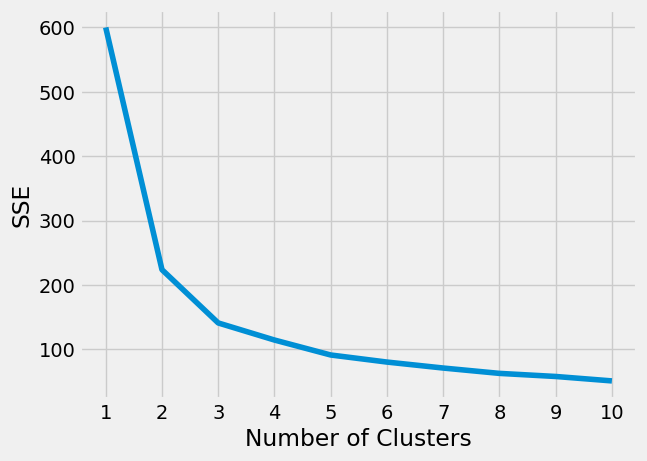

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt


kmeans_kwargs = {
    "init": "random",
    "n_init": 10,
    "max_iter": 300,
    "random_state": 42,
}

# A list holds the SSE values for each k
sse = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, **kmeans_kwargs)
    kmeans.fit(X_standardized)
    sse.append(kmeans.inertia_)

plt.style.use("fivethirtyeight")
plt.plot(range(1, 11), sse)
plt.xticks(range(1, 11))
plt.xlabel("Number of Clusters")
plt.ylabel("SSE")
plt.show()

In [ ]:
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN

cluster = KMeans(n_clusters=3, random_state=42, n_init="auto")
#cluster = DBSCAN(eps=1, min_samples=20)

model = cluster.fit(X_standardized)

In [ ]:
model.labels_

array([1, 2, 2, 2, 1, 1, 1, 1, 2, 2, 1, 1, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 2, 1, 1, 1, 2, 2, 1, 1, 1, 2, 2, 1, 2, 2, 1, 1, 2, 2, 1,
       1, 2, 1, 2, 1, 1, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 2, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=int32)

In [ ]:
X_clustered_pd = pd.DataFrame(data=X,columns=features)
X_clustered_pd['cluster'] = model.labels_
X_clustered_pd.head()


,sepal length,sepal width,petal length,petal width,cluster
0,5.1,3.5,1.4,0.2,1
1,4.9,3.0,1.4,0.2,2
2,4.7,3.2,1.3,0.2,2
3,4.6,3.1,1.5,0.2,2
4,5.0,3.6,1.4,0.2,1


In [ ]:

new_observation = [[-0.90,1.01,-1.3,-1.3]]
model.predict(new_observation)

array([1], dtype=int32)

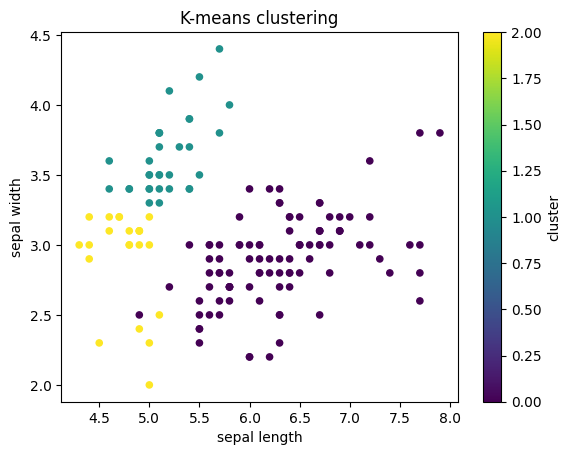

In [ ]:
#import matplotlib.pyplot as plt

X_clustered_pd.plot(kind='scatter', x='sepal length', y='sepal width', c='cluster', colormap='viridis', title='K-means clustering');

